In [1]:


import numpy as np
import pandas as pd
df = pd.read_csv(r"C:\Users\Administrator\sports-car-data-analytics\data\raw\sports-car-csv.csv" \
"")
print(df)
print(df.shape)
print(df.info())
print(df.describe())


#//--------DATA CLEANING-------//



print(df.isnull().sum())     #checking missing values
print(df.duplicated().sum())   #checking duplicated rows
df = df.drop_duplicates()

EV = df[(df["Engine Size (L)"] == "Electric")|
         (df["Engine Size (L)"] == "Electric Motor")]
HEV = df[df["Engine Size (L)"] == "Hybrid"]

print(EV.size)       #rows with electric vehicles
print(HEV.size)      #rows with hybrid vehicles

NAN = df["Engine Size (L)"].isna().sum()       #rows with NaN values
print(NAN)


df["Powertrain"] = pd.NA      #added a new column called powertrain 
print(df["Engine Size (L)"].value_counts(dropna=False))    #checks for intsances at which a condition is true


#identified all cars with hybrid or electric engines

EH = df[df["Engine Size (L)"].astype(str).str.contains("Electric|Hybrid", case=False, na=False)]
print(EH)

#filling the powertrain column
df.loc[df["Engine Size (L)"].astype(str).str.contains("Hybrid",case=False,na=False),"Powertrain"] = "Hybrid"
df.loc[df["Engine Size (L)"].astype(str).str.contains("Electric", case=False, na=False),"Powertrain"] = "Electric"

print(df.loc[df["Powertrain"].isna(),"Engine Size (L)"].value_counts(dropna=False))
print(pd.to_numeric(df["Engine Size (L)"],errors="coerce"))    #isolate numeric values
df.loc[pd.to_numeric(df["Engine Size (L)"],errors="coerce").notna() & df["Powertrain"].isna(),"Powertrain"] = "Combustion"
print(df["Powertrain"].isna().value_counts(dropna=False))    #checking unassigned rows in "powertain"
 #investigating missing info
Missing =df[df["Powertrain"].isna()]
print(df.columns.to_list())
print(Missing.columns.tolist())
print(Missing[['Car Make','Car Model','Year','Engine Size (L)','Horsepower','Torque (lb-ft)','0-60 MPH Time (seconds)','Price (in USD)','Powertrain']])
#it appears that missing engine size cars were electric
#filling their specific powertrains to electric
df.loc[df["Powertrain"].isna(),"Powertrain"] = "Electric"

#Investigating torque
print(df["Torque (lb-ft)"].isna().value_counts(dropna=False))
print(df.loc[df['Torque (lb-ft)'].isna()])    #---> missing torque values are from electric cars
#further cleaning
print(df["Torque (lb-ft)"].dropna().head(10))
print(df["Horsepower"].dropna().head(10))
print(df['Price (in USD)'].dropna().head())
df["Price (in USD)"] = pd.to_numeric(df["Price (in USD)"].astype(str).str.replace(",", "", regex=False).str.strip()
                                     ,errors="coerce")
df["Horsepower"] = pd.to_numeric(df["Horsepower"],errors='coerce')
df['0-60 MPH Time (seconds)'] = pd.to_numeric(
    df["0-60 MPH Time (seconds)"].astype(str).str.replace('<','',regex=False)
                                              ,errors='coerce')
df.loc[df["Torque (lb-ft)"] == 0.0,"Torque (lb-ft)"] = np.nan
df["Torque (lb-ft)"] = pd.to_numeric(df["Torque (lb-ft)"],errors='coerce')
df["Torque (lb-ft)"] = df['Torque (lb-ft)'].replace([0,'-'],np.nan)
df["Engine Size (L)"] = df["Engine Size (L)"].replace([0,'-'],np.nan)
df.loc[df["Engine Size (L)"] == 0,"Engine Size (L)"] = "Electric"
df.loc[df["Car Model"] == "i8", "Powertrain"] = "Hybrid"
print(df.loc[df.isnull().any(axis=1)])
print(df[df.duplicated(keep=False)])
df = df.drop_duplicates()
print(df.duplicated().sum())
print(df.info())
df.to_csv("../data/cleaned/sports_cars_cleaned.csv", index=False)
print(df.isnull().sum())
print(df.describe())



#------EXPLORATORY DATA ANALYSIS-----------//
#Univariate analysis
print(df["Price (in USD)"].mean())
print(df["Price (in USD)"].min())
print(df["Price (in USD)"].max())
print(df["Price (in USD)"].median())
print(df["Price (in USD)"].sum())
print(df["Price (in USD)"].count())
print(df.loc[df["Price (in USD)"] == df["Price (in USD)"].max()])    #Extracting the most expensive car
print(df.loc[df["Price (in USD)"] == df["Price (in USD)"].min()])    #Extracting the cheapest car
average_price = df["Price (in USD)"].mean()
print(df.loc[df["Price (in USD)"] > average_price])    #above average price
print(df.loc[df["Price (in USD)"] < average_price])    #Below average price
print(df["Price (in USD)"].quantile([0.25,0.50,0.75]))
Q1 = df["Price (in USD)"].quantile(0.25)
Q3 = df["Price (in USD)"].quantile(0.75)
IQR = Q3 - Q1
print(IQR)
#Bivariate analysis
#comparison between price and horsepower
print(df.loc[df["Horsepower"] == df["Horsepower"].max()])

print(df.loc[df["Horsepower"] == df["Horsepower"].min()])

print(df["Horsepower"].corr(df["Price (in USD)"]))
#Horsepower and Time 0-60 MPH (in seconds)
print(df["Horsepower"].corr(df["0-60 MPH Time (seconds)"]))
print(df.loc[df["0-60 MPH Time (seconds)"] == df["0-60 MPH Time (seconds)"].max()])
print(df.loc[df["0-60 MPH Time (seconds)"] == df['0-60 MPH Time (seconds)'].min()])
#Price (in USD) & year
cars_2021 = df.loc[df['Year'] == 2021]
cars_2022 = df.loc[df['Year'] == 2022]
print(cars_2021['Price (in USD)'].describe())
print(cars_2022['Price (in USD)'].describe())
print(cars_2022["Price (in USD)"].median() - cars_2021["Price (in USD)"].median())
print(len(cars_2022))
print(len(cars_2021))
Tesla = df.loc[df["Car Make"].str.contains('Tesla',case=False,na=False)]
Tesla_2021 = Tesla.loc[Tesla['Year'] == 2021]
Tesla_2022 = Tesla.loc[Tesla['Year'] == 2022]
print(len(Tesla_2021))
print(len(Tesla_2022))
print(Tesla_2021['Price (in USD)'].describe())
print(Tesla_2022['Price (in USD)'].describe())
#Multivariate EDA
group = df.groupby('Car Make')
GROUP = group[['Price (in USD)','Horsepower']].mean().round(2)
print(GROUP)
print(GROUP.sort_values(by='Price (in USD)',ascending=False).head(10))  #sort by average price
print(GROUP.sort_values(by= 'Horsepower',ascending=False).head(10))




             
                                               




         Car Make Car Model  Year Engine Size (L) Horsepower Torque (lb-ft)  \
0         Porsche       911  2022               3        379            331   
1     Lamborghini   Huracan  2021             5.2        630            443   
2         Ferrari   488 GTB  2022             3.9        661            561   
3            Audi        R8  2022             5.2        562            406   
4         McLaren      720S  2021               4        710            568   
...           ...       ...   ...             ...        ...            ...   
1002   Koenigsegg     Jesko  2022               5       1280           1106   
1003        Lotus     Evija  2021  Electric Motor       1972           1254   
1004      McLaren     Senna  2021               4        789            590   
1005       Pagani    Huayra  2021               6        764            738   
1006        Rimac    Nevera  2021  Electric Motor       1888           1696   

     0-60 MPH Time (seconds) Price (in USD)  
0    

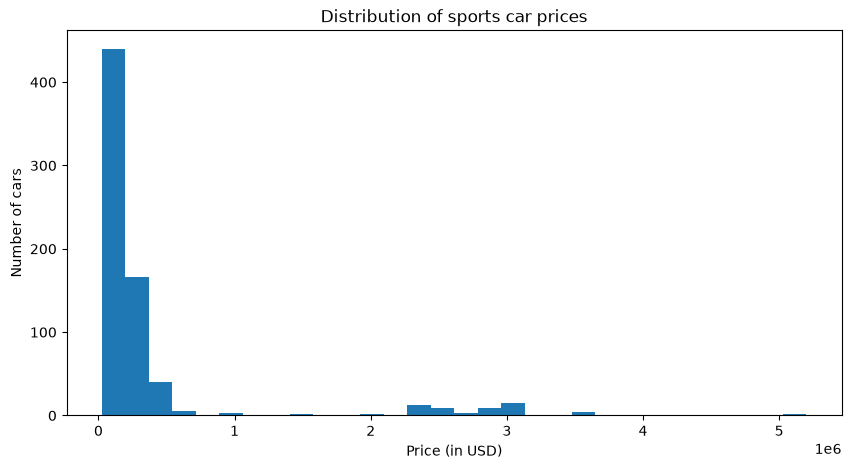

None


In [2]:

#-----DATA VISUALIZATION-----//


import matplotlib.pyplot as plt
#prices visualization
plt.figure(figsize=(10,5))
plt.hist(df["Price (in USD)"],bins=30)
plt.title("Distribution of sports car prices")
plt.xlabel("Price (in USD)")
plt.ylabel("Number of cars")
print(plt.show())

                                               


### Interpretation: Distribution of Sports Car Prices

The histogram shows that sports car prices are right-skewed. Most cars are concentrated in the lower price ranges, while a small number of extremely expensive cars extend the distribution toward the right.

These high-priced vehicles increase the mean price, making it higher than the median. This suggests that the median may better represent the typical car price in this dataset.

**Limitation:** The histogram shows the distribution of prices but does not explain why some cars are more expensive than others.

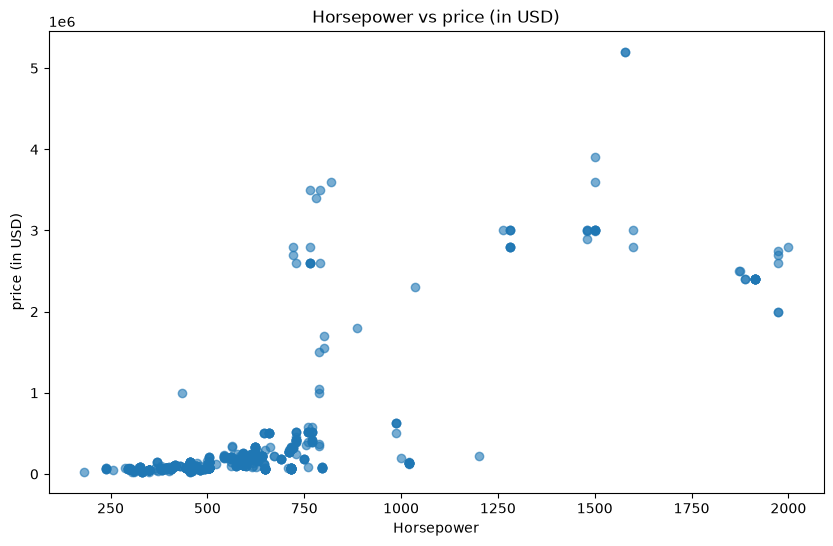

None


In [3]:
#Horsepower and prices
plt.figure(figsize=(10,6))
plt.scatter(df["Horsepower"],
            df['Price (in USD)'],alpha=0.6
)
plt.title("Horsepower vs price (in USD)")
plt.xlabel('Horsepower')
plt.ylabel('price (in USD)')
print(plt.show())


**###Interpretation:Horsepower and Price (in USD)**

There is a positive relationship between horsepower and price.
However the points are widely dispersed particularly among high horsepower cars.
Some cars which are highly expensive tend to share the same horsepower range with less expensive cars
This suggests that horsepower is not the only factor associated with car prices.

**Limitation**:this plot shows association not causation,other prices including car make,Car model,Torque may also contribute to price differences

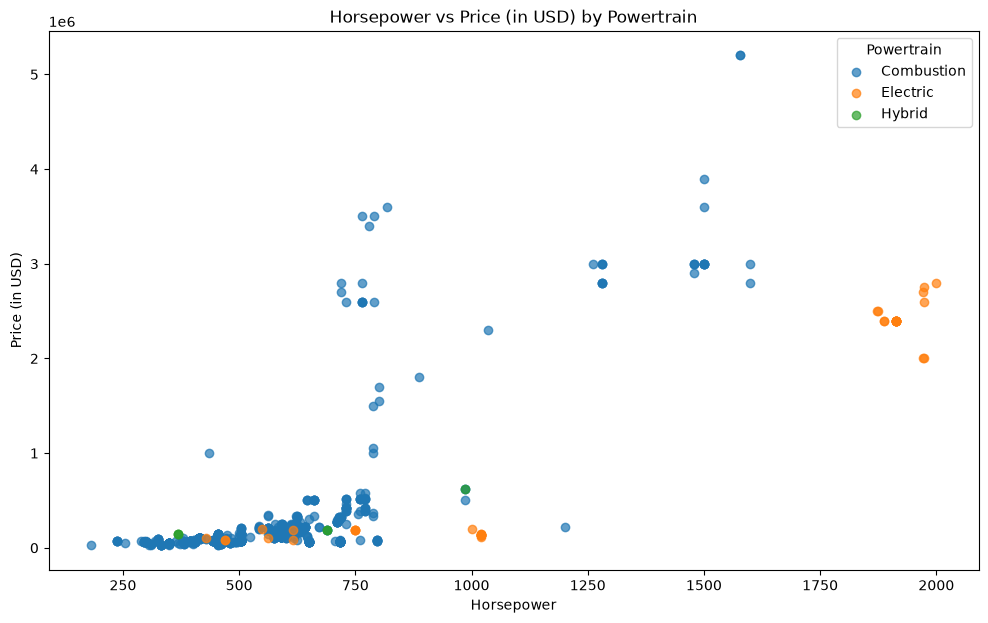

None


In [4]:
#Horsepower vs Price (in USD) by Powretrain
plt.figure(figsize=(12,7))
for powertrain ,Group in df.groupby("Powertrain"):
    plt.scatter(Group["Horsepower"],
                Group["Price (in USD)"],
                label = powertrain,
                alpha=0.7
)
plt.title("Horsepower vs Price (in USD) by Powertrain")
plt.xlabel("Horsepower")
plt.ylabel("Price (in USD)")
plt.legend(title="Powertrain")
print(plt.show())

                                                      
                                               


### Interpretation: Horsepower vs. Price by Powertrain

The scatter plot separates cars by powertrain, allowing us to compare combustion, electric, and hybrid vehicles.

The different groups overlap in some areas, meaning that cars with different powertrains can have similar horsepower and prices. Some electric vehicles also appear among the high-horsepower and high-price cars.

However, the number of observations differs between powertrain categories, so these patterns should be interpreted cautiously.

**Limitation:** This plot shows patterns within the dataset but does not establish that a particular powertrain causes higher horsepower or prices.

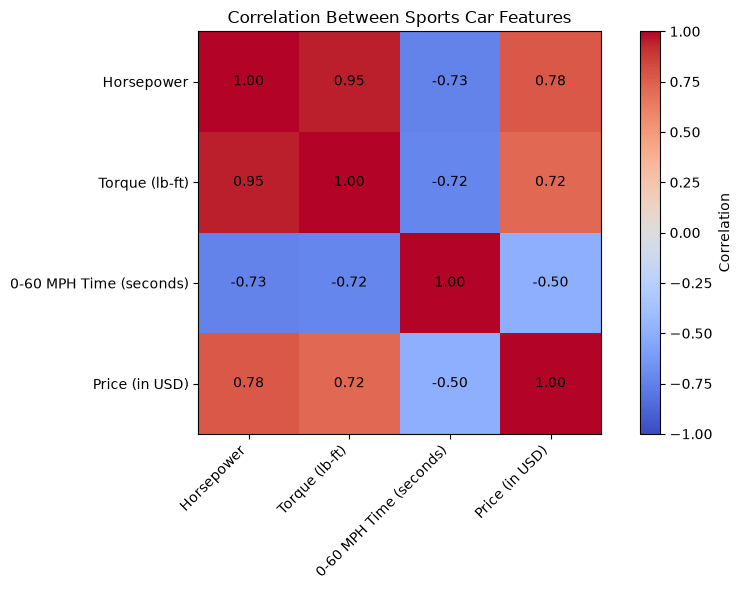

In [5]:
#Correlation Heat Map


columns = [
    "Horsepower",
    "Torque (lb-ft)",
    "0-60 MPH Time (seconds)",
    "Price (in USD)"
]

corr = df[columns].corr()

plt.figure(figsize=(9, 6))

plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(range(len(columns)), columns, rotation=45, ha="right")
plt.yticks(range(len(columns)), columns)

for i in range(len(columns)):
    for j in range(len(columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.title("Correlation Between Sports Car Features")
plt.tight_layout()
plt.show()


### Interpretation: Correlation Between Sports Car Features

The correlation heatmap reveals several relationships between numerical features in the dataset.

- **Horsepower and price (0.78):** A strong positive relationship suggests that cars with higher horsepower tend to be more expensive.
- **Horsepower and torque (0.95):** A very strong positive relationship indicates that these two performance measurements tend to increase together.
- **Horsepower and 0–60 time (-0.73):** A strong negative relationship suggests that higher-horsepower cars generally achieve quicker acceleration.
- **Price and 0–60 time (-0.50):** A moderate negative relationship suggests that more expensive cars tend to have quicker acceleration.

**Conclusion:** Performance characteristics are associated with car prices and acceleration, but these relationships do not establish causation. Other vehicle characteristics may also influence the results.

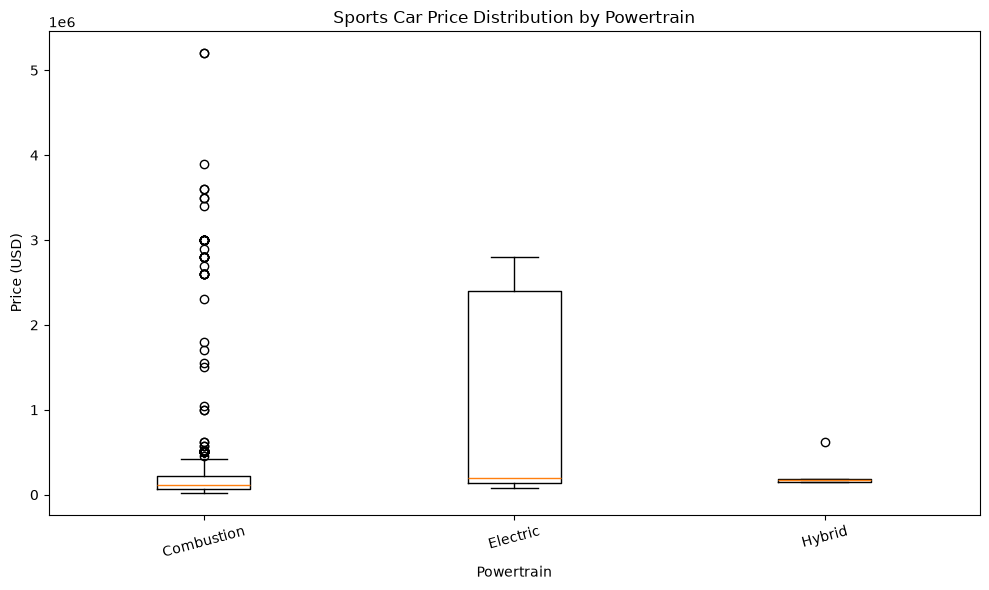

In [6]:
#A Boxplot comparing sports car prices by powertrain

import matplotlib.pyplot as plt

# Keep rows with a known powertrain and price
plot_df = df.dropna(subset=["Powertrain", "Price (in USD)"])

# Arrange prices into groups
powertrains = plot_df["Powertrain"].unique()

price_groups = [
    plot_df.loc[
        plot_df["Powertrain"] == powertrain,
        "Price (in USD)"
    ]
    for powertrain in powertrains
]

plt.figure(figsize=(10, 6))

plt.boxplot(price_groups, tick_labels=powertrains)

plt.title("Sports Car Price Distribution by Powertrain")
plt.xlabel("Powertrain")
plt.ylabel("Price (USD)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### Interpretation: Sports Car Price Distribution by Powertrain

The box plot shows differences in price distributions across combustion, electric, and hybrid vehicles.

- **Combustion vehicles:** Most prices are concentrated in a lower range, with numerous potential outliers at much higher prices.
- **Electric vehicles:** Prices have a wide spread, indicating substantial variation within this category. Some electric vehicles are priced in the millions of dollars.
- **Hybrid vehicles:** The observed prices appear more concentrated, with one visible potential outlier. However, the small number of observations limits the conclusions we can draw.

**Conclusion:** Price variation differs across the powertrain categories in this dataset. These differences should be interpreted cautiously because the groups may have different sample sizes and vehicle models.

**Limitation:** A point beyond a box plot's whiskers is a potential statistical outlier, not necessarily an error in the data.